# Baseline 2: Multivariate Return Forecasting & Walk-Forward Evaluation (NFLX)

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset, check_no_lookahead, ALL_FEATURES
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import (
    compare_models,
    diebold_mariano,
    dm_verdict,
    directional_accuracy_test,
    out_of_sample_r2,
)
from tslab.plots import plot_price_forecasts

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

# Load NFLX market data and build the supervised feature table (predicting t+1 log return)
frame = load_market_data()
dataset = make_dataset(frame, horizon=1)

# Separate the most recent day (no known tomorrow yet) and drop NaN targets
latest_row = dataset.iloc[[-1]]
dataset = dataset.dropna(subset=["target_return"])

print("Target Ticker              :", config.TARGET_TICKER)
print("Modelling table rows       :", len(dataset))
print("Number of predictors       :", len(ALL_FEATURES))
print("First modelling date       :", dataset.index[0].date())
print("Last scored date           :", dataset.index[-1].date())

Loaded 2981 trading days of NFLX, 2015-01-02 to 2026-11-09, with 7 predictor series.
Target Ticker              : NFLX
Modelling table rows       : 2781
Number of predictors       : 47
First modelling date       : 2015-10-16
Last scored date           : 2026-11-06


In [2]:
# Verify that no feature in tslab.features peeks into future rows
check_no_lookahead(frame, n_checks=8)
print("PASSED: check_no_lookahead confirmed zero future leakage across all predictors.")

PASSED: check_no_lookahead confirmed zero future leakage across all predictors.


In [3]:
X = dataset[ALL_FEATURES]
y = dataset["target_return"]

splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))
print(f"Total walk-forward folds: {len(splits)} (Initial train = {config.INITIAL_TRAIN}, Test step = {config.TEST_SIZE})")
display(describe_splits(splits, dataset.index).head(3))
display(describe_splits(splits, dataset.index).tail(3))

Total walk-forward folds: 29 (Initial train = 1000, Test step = 63)


,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
1,1000,2015-10-16,2019-10-07,63,2019-10-08,2020-01-07
2,1063,2015-10-16,2020-01-07,63,2020-01-08,2020-04-07
3,1126,2015-10-16,2020-04-07,63,2020-04-08,2020-07-08


,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
27,2638,2015-10-16,2026-04-15,63,2026-04-16,2026-07-16
28,2701,2015-10-16,2026-07-16,63,2026-07-17,2026-10-14
29,2764,2015-10-16,2026-10-14,17,2026-10-15,2026-11-06


In [4]:
# Rule: Never tune on the test period. Use only the first INITIAL_TRAIN rows.
tuning_X = X.iloc[: config.INITIAL_TRAIN]
tuning_y = y.iloc[: config.INITIAL_TRAIN]

inner_splits = list(walk_forward_splits(len(tuning_X), initial_train=500, test_size=100))

def tuning_score(model_factory):
    predicted = walk_forward_predict(model_factory, tuning_X, tuning_y, inner_splits)
    mask = predicted.notna()
    return float(np.mean((tuning_y[mask] - predicted[mask]) ** 2))

# 1. Tune Ridge alpha
alphas = [1, 10, 100, 1000, 10000, 100000]
ridge_results = {a: tuning_score(lambda alpha=a: Ridge(alpha=alpha)) for a in alphas}
best_alpha = min(ridge_results, key=ridge_results.get)
display(pd.Series(ridge_results, name="Inner Tuning MSE").to_frame().T)
print("Selected Ridge alpha:", best_alpha)

# 2. Tune Gradient Boosting depth and learning rate
def make_boosting(max_depth=3, learning_rate=0.03, max_iter=200):
    return HistGradientBoostingRegressor(
        loss="squared_error",
        max_depth=max_depth,
        learning_rate=learning_rate,
        max_iter=max_iter,
        min_samples_leaf=40,
        l2_regularization=1.0,
        random_state=config.SEED,
    )

grid = [(d, lr) for d in (2, 3, 5) for lr in (0.01, 0.03)]
boost_results = {
    combo: tuning_score(lambda c=combo: make_boosting(max_depth=c[0], learning_rate=c[1]))
    for combo in grid
}
best_depth, best_rate = min(boost_results, key=boost_results.get)
display(pd.Series(boost_results, name="Inner Tuning MSE").rename_axis(["max_depth", "learning_rate"]).to_frame().round(8))
print(f"Selected Gradient Boosting settings: max_depth={best_depth}, learning_rate={best_rate}")

,1,10,100,1000,10000,100000
Inner Tuning MSE,0.000965,0.000878,0.000725,0.000658,0.000648,0.000647


Selected Ridge alpha: 100000


Inner Tuning MSE
max_depth learning_rate                  
2         0.01                   0.000664
          0.03                   0.000680
3         0.01                   0.000670
          0.03                   0.000693
5         0.01                   0.000669
          0.03                   0.000704

Selected Gradient Boosting settings: max_depth=2, learning_rate=0.01


In [5]:
predictions = {}

# 1. Ridge Regression (all predictors, scaler fit inside each training fold automatically)
started = time.time()
predictions["Ridge"] = walk_forward_predict(lambda: Ridge(alpha=best_alpha), X, y, splits)
print(f"Ridge walk-forward completed in {time.time() - started:.1f}s")

# 2. HistGradientBoostingRegressor (all predictors)
started = time.time()
predictions["Gradient boosting"] = walk_forward_predict(
    lambda: make_boosting(max_depth=best_depth, learning_rate=best_rate), X, y, splits
)
print(f"Gradient boosting walk-forward completed in {time.time() - started:.1f}s")

# 3. ARMAX(1,0) with lagged 7 market predictors (from Notebook 3, Step 5)
log_close = np.log(frame["Close"])
stock_return = log_close.diff()
position_in_frame = {date: i for i, date in enumerate(frame.index)}

predictor_changes = pd.DataFrame(index=frame.index)
for name in ["SP500", "TECH", "GOLD", "BRENT", "USD", "VIX"]:
    predictor_changes[name] = np.log(frame[name]).diff()
predictor_changes["US10Y"] = frame["US10Y"].diff()

# Shift by 1 day so predictors for day s are known at close of day s-1
exog_all = predictor_changes.shift(1)
FIRST_USABLE = 2

armax_preds = pd.Series(np.nan, index=dataset.index)
for train_idx, test_idx in splits:
    last_train_pos = position_in_frame[dataset.index[train_idx[-1]]]
    first_test_pos = position_in_frame[dataset.index[test_idx[0]]]
    last_test_pos = position_in_frame[dataset.index[test_idx[-1]]]

    y_train = stock_return.iloc[FIRST_USABLE : last_train_pos + 1]
    x_train = exog_all.iloc[FIRST_USABLE : last_train_pos + 1]
    fitted = SARIMAX(y_train, exog=x_train, order=(1, 0, 0), trend="c").fit(disp=False)

    y_all = stock_return.iloc[FIRST_USABLE : last_test_pos + 2]
    x_all = exog_all.iloc[FIRST_USABLE : last_test_pos + 2]
    carried = fitted.apply(y_all, exog=x_all, refit=False)

    start = first_test_pos + 1 - FIRST_USABLE
    end = last_test_pos + 1 - FIRST_USABLE
    armax_preds.iloc[test_idx] = carried.get_prediction(start=start, end=end).predicted_mean.values

predictions["ARMAX(1,0), 7 predictors"] = armax_preds
print("ARMAX(1,0) walk-forward completed.")

Ridge walk-forward completed in 0.1s
Gradient boosting walk-forward completed in 4.4s
ARMAX(1,0) walk-forward completed.


In [6]:
# Compare all models on price RMSE, MAE, MAPE, Directional Accuracy, and Out-of-Sample R2 (returns)
# Note: compare_models automatically includes the Naive (no change) row
scores = compare_models(dataset, predictions)
display(scores.round(4))

# Statistical significance tests against the Naive forecast (0 return)
scored_rows = pd.concat(predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]

dm_rows = []
for name, series in predictions.items():
    pred_vals = series.loc[scored_rows]
    stat, p_dm = diebold_mariano(actual, pred_vals, np.zeros(len(scored_rows)))
    hit_rate, p_dir = directional_accuracy_test(actual, pred_vals)
    dm_rows.append({
        "Model": name,
        "DM statistic vs naive": stat,
        "DM p-value": p_dm,
        "DM Verdict": dm_verdict(stat, p_dm),
        "Directional accuracy": hit_rate,
        "Hit rate p-value (vs 50%)": p_dir,
    })

dm_summary = pd.DataFrame(dm_rows).set_index("Model")
display(dm_summary.round(4))

,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),1.4790,0.9663,1.7895,NaN,0.0000
Ridge,1.4806,0.9670,1.7916,0.5065,-0.0008
Gradient boosting,1.4878,0.9726,1.8023,0.4840,-0.0132
"ARMAX(1,0), 7 predictors",1.4896,0.9742,1.8032,0.4969,-0.0078


,DM statistic vs naive,DM p-value,DM Verdict,Directional accuracy,Hit rate p-value (vs 50%)
Model,,,,,
Ridge,0.4405,0.6596,No significant difference,0.5065,0.6022
Gradient boosting,1.8057,0.0711,No significant difference,0.4840,0.1845
"ARMAX(1,0), 7 predictors",1.4170,0.1567,No significant difference,0.4969,0.8127


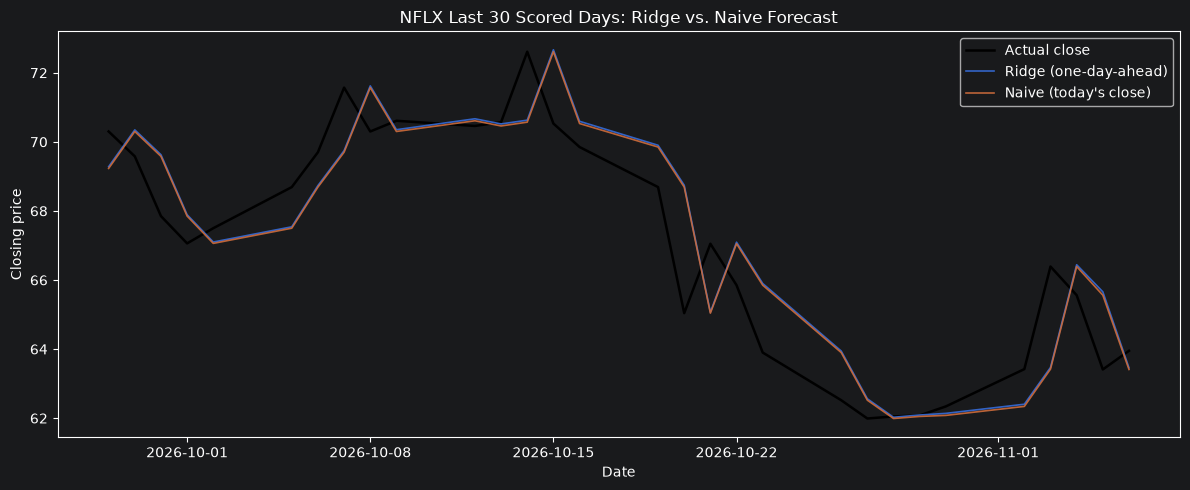

In [7]:
scored = dataset.loc[scored_rows]
best_name = scores.drop(index="Naive (no change)")["Out-of-sample R2 (returns)"].idxmax()

plot_price_forecasts(
    dates=scored.index,
    actual=scored["target_close"].values,
    forecasts={
        f"{best_name} (one-day-ahead)": (scored["close"] * np.exp(predictions[best_name].loc[scored_rows])).values,
        "Naive (today's close)": scored["close"].values,
    },
    title=f"NFLX Last 30 Scored Days: {best_name} vs. Naive Forecast",
    last_n=30,
)